# Flagging Scam Texts Before Customers Open Them

**INFO 4360 Complex Data Analytics, Final Report (Phase 3)**
**Team:** Julia Rasul and Nicole Benton · University of Denver · Fall 2026
**Path:** A (Prediction / Classification)

**Contents:** 1. Problem · 2. Data · 3. Phase 2 recap · 4. Tool choice · 5. Modeling · 6. Key findings · 7. Business implications · 8. Ethics and privacy · 9. AI usage log · References

## 1. Problem statement

Americans reported losing $470 million to text message scams in 2024 (FTC, 2025), and most of us have received a fake "your package could not be delivered" or "you won a prize" text. Our stakeholder is the fraud team at a mobile carrier, whose job is to stop these messages before they reach customers. We built a fast, cheap text classifier that estimates the chance a message is a scam, so the carrier can block the clear scams, warn customers about the suspicious ones, and deliver real messages normally. Because a carrier screens millions of texts a day, the model has to be accurate, explainable, and inexpensive to run on every message.

In [1]:
import sys, os, html, re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import hstack, csr_matrix
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

sys.path.append("..")
from src.scamfeatures import signal_features   # shared text signals (also used by the Scam Checker)

pd.set_option("display.max_colwidth", 120)
RANDOM_STATE = 42

## 2. Data

**Source:** [SMS Phishing Dataset for Machine Learning and Pattern Recognition](https://data.mendeley.com/datasets/f45bkkt8pr/1) (Mishra & Soni, 2022), Mendeley Data. Each row is a real text message with a label (**ham** = legitimate, **spam** = unwanted marketing, **smishing** = a scam after money or personal details) and yes/no flags for URL, EMAIL and PHONE.

**Cleaning:** we standardized label casing (`Smishing`/`smishing`, `Spam`/`spam`), replaced the `&lt;#&gt;` placeholder code, decoded HTML codes, trimmed extra spaces, converted the flags to True/False, and removed duplicates. The file has 95 exact duplicate rows but 140 repeated message texts (the same text sometimes appears with different flags or labels). We dropped all 140 so the same message can never appear in both the training and test sets.

In [2]:
# Load and clean the data (same cleaning as Phase 2)
def load_data(path):
    df = pd.read_csv(path)
    df["LABEL"] = df["LABEL"].str.strip().str.lower()                     # Smishing/smishing, Spam/spam
    df["TEXT"] = (df["TEXT"].str.replace("&lt;#&gt;", " ", regex=False)   # placeholder code
                  .str.strip().apply(html.unescape))                       # HTML codes like &amp;
    for c in ["URL", "EMAIL", "PHONE"]:
        df[c] = df[c].str.lower().eq("yes")                                # yes/no to True/False
    return df

raw = load_data("../data/Dataset_5971.csv")
print("Raw rows:", len(raw))
print("Exact duplicate rows:", raw.duplicated().sum())
print("Duplicate message texts:", raw["TEXT"].duplicated().sum())

# Drop every repeated text so the same message can't land in both train and test
df = raw.drop_duplicates(subset="TEXT").reset_index(drop=True)
df["scam"] = (df["LABEL"] != "ham").astype(int)                            # ham = 0, spam or smishing = 1
print("Rows after removing duplicate texts:", len(df))

Raw rows: 5971
Exact duplicate rows: 95
Duplicate message texts: 140
Rows after removing duplicate texts: 5831


,messages,share %
LABEL,,
ham,4834,82.9
smishing,543,9.3
spam,454,7.8


,messages,share %
scam,,
ham,4834,82.9
scam,997,17.1


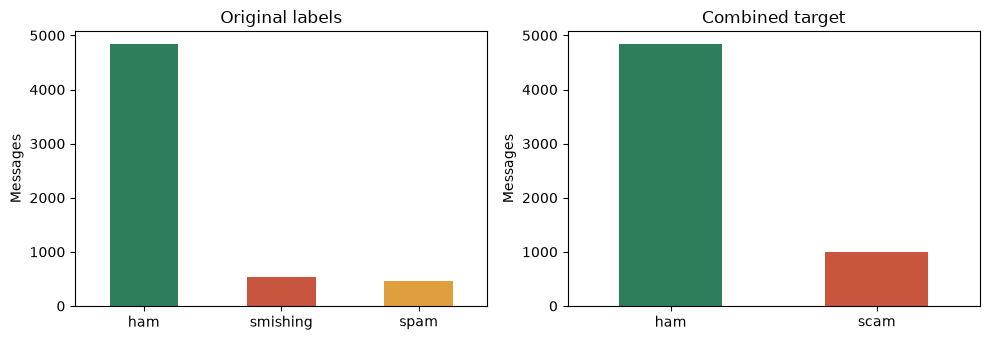

In [3]:
# Class balance, before and after combining spam and smishing
three = df["LABEL"].value_counts()
two = df["scam"].map({0: "ham", 1: "scam"}).value_counts()
display(pd.DataFrame({"messages": three, "share %": (three / len(df) * 100).round(1)}))
display(pd.DataFrame({"messages": two, "share %": (two / len(df) * 100).round(1)}))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
three.plot.bar(ax=axes[0], rot=0, color=["#2E7D5B", "#C8553D", "#E09F3E"], title="Original labels")
two.plot.bar(ax=axes[1], rot=0, color=["#2E7D5B", "#C8553D"], title="Combined target")
for ax in axes: ax.set_ylabel("Messages"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

After cleaning, 5,831 messages remain. Only 17.1% are scams once spam and smishing are combined, so the classes are imbalanced: a model that always answers "ham" would already be 82.9% accurate while catching zero scams. That is why we judge models mainly on scam recall, precision and F1, not accuracy alone.

## 3. Recap of Phase 2 findings (refined)

In Phase 2 we explored message length, distinctive words, text signals and sentiment. The tables below recompute those findings on the final cleaned data using the same `signal_features` function the model uses, so the exploration and the model are guaranteed to measure the same thing.

In [4]:
# Phase 2 text signals by original label (spam and smishing look alike, ham stands apart)
sig = signal_features(df["TEXT"])
sig["LABEL"] = df["LABEL"].values
summary = sig.groupby("LABEL").mean().T.round(2)[["ham", "spam", "smishing"]]
summary

LABEL,ham,spam,smishing
word_count,14.11,23.10,22.96
digits,0.32,12.37,17.04
has_phone,0.00,0.37,0.73
has_shortcode,0.00,0.50,0.39
has_url,0.00,0.23,0.20
has_currency,0.00,0.21,0.31
caps_pct,5.69,11.83,11.06
exclaim,0.18,0.56,0.65
call_to_action,0.09,0.74,0.77
sentiment,0.17,0.35,0.54


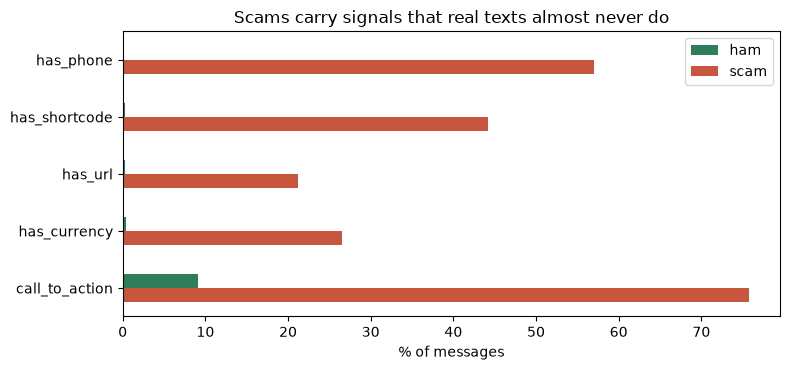

Median words: ham 11.0 | scam 24.0
Mean digits: ham 0.32 | scam 14.91


In [5]:
# Share of messages with each yes/no signal, ham vs scam
flags = ["has_phone", "has_shortcode", "has_url", "has_currency", "call_to_action"]
share = sig[flags].groupby(df["scam"].map({0: "ham", 1: "scam"}).values).mean().T * 100
ax = share.plot.barh(figsize=(8, 3.8), color=["#2E7D5B", "#C8553D"])
ax.set_xlabel("% of messages"); ax.set_title("Scams carry signals that real texts almost never do")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

print("Median words: ham", sig.loc[df.scam == 0, "word_count"].median(),
      "| scam", sig.loc[df.scam == 1, "word_count"].median())
print("Mean digits: ham", round(sig.loc[df.scam == 0, "digits"].mean(), 2),
      "| scam", round(sig.loc[df.scam == 1, "digits"].mean(), 2))

Scams are built differently from real texts. Real messages are short (median 11 words vs. 24 for scams) and almost never contain a phone number, short code, link or currency symbol. Scams average about 15 digits per message vs. 0.3 for ham, use twice the share of capital letters, and about three in four ask the reader to call, text, reply or click, compared with fewer than one in ten real texts.

Spam and smishing look nearly identical on every signal, while ham stands apart. This is why we combined them into one "scam" target (ham = 0, scam = 1).

In [6]:
# Most distinctive words per label (share of messages containing the word vs all other labels)
def tokenize(text):
    return [w for w in re.findall(r"[a-z']+", text.lower()) if w not in ENGLISH_STOP_WORDS and len(w) > 1]

def distinctive_words(label, n=8, min_count=10):
    is_a = df["LABEL"] == label
    ca = Counter(w for t in df.loc[is_a, "TEXT"] for w in set(tokenize(t)))
    cb = Counter(w for t in df.loc[~is_a, "TEXT"] for w in set(tokenize(t)))
    rows = [(w, ca[w] / is_a.sum() * 100, cb[w] / (~is_a).sum() * 100) for w in ca if ca[w] >= min_count]
    out = pd.DataFrame(rows, columns=["word", "% in label", "% in others"])
    out["log2 ratio"] = np.log2((out["% in label"] + 0.5) / (out["% in others"] + 0.5))
    return out.sort_values("log2 ratio", ascending=False).head(n).round(1).reset_index(drop=True)

pd.concat({lab: distinctive_words(lab)[["word", "% in label"]] for lab in ["ham", "spam", "smishing"]}, axis=1)

ham                 spam               smishing           
    word % in label      word % in label        word % in label
0   i'll        3.3       txt       25.8       claim       27.4
1    lor        3.0      tone        9.0       prize       22.7
2  later        2.7       win       11.5  guaranteed       14.0
3   come        4.5  ringtone        5.9    customer       20.6
4     ok        5.7     nokia        9.5         won       13.8
5    i'm        7.4      stop       16.5     awarded        9.8
6     da        2.6     tones        4.6     contact       17.1
7  doing        1.8        uk       10.6      urgent       15.1

Each group has its own vocabulary. Ham is casual and conversational ("later," "ok," "sorry," plus slang like "lor" and "da"). Spam advertises subscriptions and ringtones ("txt," "ringtone," "nokia," "stop"). Smishing pressures the reader to act on a fake prize or account ("claim," "prize," "urgent," "customer"). Words like "nokia" and "ringtone" also show the messages are older and mostly from the UK and India, which matters for the limitations below.

In [7]:
# VADER sentiment by label: scams sound more upbeat (prizes, rewards)
sig.groupby("LABEL")["sentiment"].agg(["mean", "median"]).round(2).loc[["ham", "spam", "smishing"]]

,mean,median
LABEL,,
ham,0.17,0.00
spam,0.35,0.46
smishing,0.54,0.70


Scams sound more positive. Smishing has the highest median sentiment (0.70), followed by spam (0.46), while the typical real text is neutral (0.00). Scams promise prizes and rewards, so an upbeat tone is a weak warning sign.

## 4. Tool choice: why classical NLP was enough

We did not use an LLM in the model or to label any data. Classical tools (pandas, regex, scikit-learn TF-IDF and logistic regression, VADER) were enough for three reasons:

1. The labels already existed. In Phase 1 we planned to have Claude relabel about 300 scam texts to check the spam vs. smishing split. Phase 2 showed the two classes are nearly identical, so we combined them, and the split we planned to check no longer affects the model.
2. The red flags are easy to compute. Phone numbers, links, digits, currency and calls to action are all captured with a few regular expressions, and Section 5 shows these simple signals carry most of the predictive power.
3. Cost and speed. A carrier screens millions of texts a day. Our model scores a message in milliseconds at no cost, while an API call per message would add cost and delay for every text.

API usage: 0 tokens, $0. We used Claude only as a coding and writing assistant through the chat interface (see the AI usage log in Section 9), never to label, classify or generate data.

## 5. Modeling (Path A)

### 5.1 Train/test split and features

We use a stratified 80/20 split so both sets keep the same 17.1% scam share. Every feature transformation is fit on the training set only and then applied to the test set, so no information about the test messages leaks into training.

* **Word features (content):** TF-IDF on words that appear in at least 2 training messages and fewer than 90% of them, with English stop words removed.
* **Text signals (style):** the 10 Phase 2 signals (word count, digits, phone number, short code, link, currency symbol, capital letters, exclamation points, call to action, VADER sentiment), standardized so they share a scale with the word features.

In [8]:
# 80/20 split, stratified so both sets keep the same scam share
train_df, test_df = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE, stratify=df["scam"])
y_train, y_test = train_df["scam"], test_df["scam"]
print(f"Train: {len(train_df)} messages, {y_train.mean():.1%} scam")
print(f"Test:  {len(test_df)} messages, {y_test.mean():.1%} scam")

Train: 4664 messages, 17.1% scam
Test:  1167 messages, 17.1% scam


In [9]:
# Word features: TF-IDF vocabulary learned from the training texts only
tfidf = TfidfVectorizer(lowercase=True, stop_words="english", min_df=2, max_df=0.9)
X_train_words = tfidf.fit_transform(train_df["TEXT"])
X_test_words = tfidf.transform(test_df["TEXT"])

# Style features: the 10 Phase 2 text signals, scaled with training data only
S_train = signal_features(train_df["TEXT"])
S_test = signal_features(test_df["TEXT"])
scaler = StandardScaler()
S_train_scaled = scaler.fit_transform(S_train)
S_test_scaled = scaler.transform(S_test)

# Words and signals side by side
X_train_B = hstack([X_train_words, csr_matrix(S_train_scaled)]).tocsr()
X_test_B = hstack([X_test_words, csr_matrix(S_test_scaled)]).tocsr()
print("Word features:", X_train_words.shape[1], "| signals:", S_train.shape[1], "| combined:", X_train_B.shape[1])

Word features: 3465 | signals: 10 | combined: 3475


### 5.2 Models, baseline, and training vs. test scores

We compare a majority class baseline (always predict ham) with three models:

* **Model A:** Multinomial Naive Bayes on words only, a standard text baseline.
* **Model B:** Logistic regression on words plus the 10 text signals.
* **Model C:** the same as Model B with `class_weight="balanced"`, which gives the rarer scam class more weight during training. This is our final model.

In [10]:
# Train the baseline and the three models
models = {
    "Baseline: always ham": (DummyClassifier(strategy="most_frequent"), X_train_words, X_test_words),
    "Model A: Naive Bayes (words)": (MultinomialNB(), X_train_words, X_test_words),
    "Model B: Logistic regression (words + signals)": (LogisticRegression(max_iter=1000), X_train_B, X_test_B),
    "Model C: Balanced logistic regression (words + signals)":
        (LogisticRegression(max_iter=1000, class_weight="balanced"), X_train_B, X_test_B),
}
rows, preds = [], {}
for name, (m, Xtr, Xte) in models.items():
    m.fit(Xtr, y_train)
    for split, X, y in [("train", Xtr, y_train), ("test", Xte, y_test)]:
        p = m.predict(X)
        rows.append({"model": name, "set": split, "accuracy": accuracy_score(y, p),
                     "scam precision": precision_score(y, p, zero_division=0),
                     "scam recall": recall_score(y, p), "scam F1": f1_score(y, p)})
        if split == "test": preds[name] = p

results = pd.DataFrame(rows).round(3)
results.pivot(index="model", columns="set", values=["accuracy", "scam F1", "scam recall", "scam precision"])

accuracy         \
set                                                         test  train   
model                                                                     
Baseline: always ham                                       0.829  0.829   
Model A: Naive Bayes (words)                               0.966  0.984   
Model B: Logistic regression (words + signals)             0.980  0.984   
Model C: Balanced logistic regression (words + signals)    0.983  0.987   

                                                        scam F1         \
set                                                        test  train   
model                                                                    
Baseline: always ham                                      0.000  0.000   
Model A: Naive Bayes (words)                              0.891  0.952   
Model B: Logistic regression (words + signals)            0.940  0.951   
Model C: Balanced logistic regression (words + signals)   0.950  0.961   

                                                        scam recall         \
set                                                            test  train   
model                                                                        
Baseline: always ham                                          0.000  0.000   
Model A: Naive Bayes (words)                                  0.815  0.915   
Model B: Logistic regression (words + signals)                0.905  0.925   
Model C: Balanced logistic regression (words + signals)       0.945  0.967   

                                                        scam precision         
set                                                               test  train  
model                                                                          
Baseline: always ham                                             0.000  0.000  
Model A: Naive Bayes (words)                                     0.982  0.993  
Model B: Logistic regression (words + signals)                   0.978  0.979  
Model C: Balanced logistic regression (words + signals)          0.955  0.955

**Reading the table:**

* **Baseline:** 82.9% accuracy but a scam recall of 0. Accuracy alone would make a useless model look decent.
* **Adding the text signals helped most.** Recall rose from 0.815 (Model A, words only) to 0.905 (Model B), and balancing the classes raised it to 0.945 (Model C). Test F1 improved from 0.891 to 0.940 to 0.950. Model C gives up a little precision (0.978 to 0.955) to catch more scams, which is the right trade for a fraud team, because a missed scam can cost a customer money while a warning on a real text is only an annoyance.
* **Overfitting:** Naive Bayes shows the largest gap between training and test F1 (0.952 vs. 0.891), so it partly memorizes training vocabulary. Both logistic regression models have small gaps (about 0.01 in F1 and 0.004 in accuracy), so they generalize well. Neither model underfits: both are far above the baseline on every metric.

In [11]:
# 5-fold cross validation on the training set: is the test score a lucky split?
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
final = models["Model C: Balanced logistic regression (words + signals)"][0]
cv_f1 = cross_val_score(LogisticRegression(max_iter=1000, class_weight="balanced"), X_train_B, y_train, cv=cv, scoring="f1")
print("Model C scam F1 by fold:", cv_f1.round(3))
print(f"Mean {cv_f1.mean():.3f}, std {cv_f1.std():.3f}")

Model C scam F1 by fold: [0.938 0.946 0.965 0.94  0.938]
Mean 0.945, std 0.010


Cross validation on the training set gives a mean F1 of 0.945 with a standard deviation of 0.010, very close to the 0.950 test F1. The test result is not a lucky split.

### 5.3 Confusion matrices

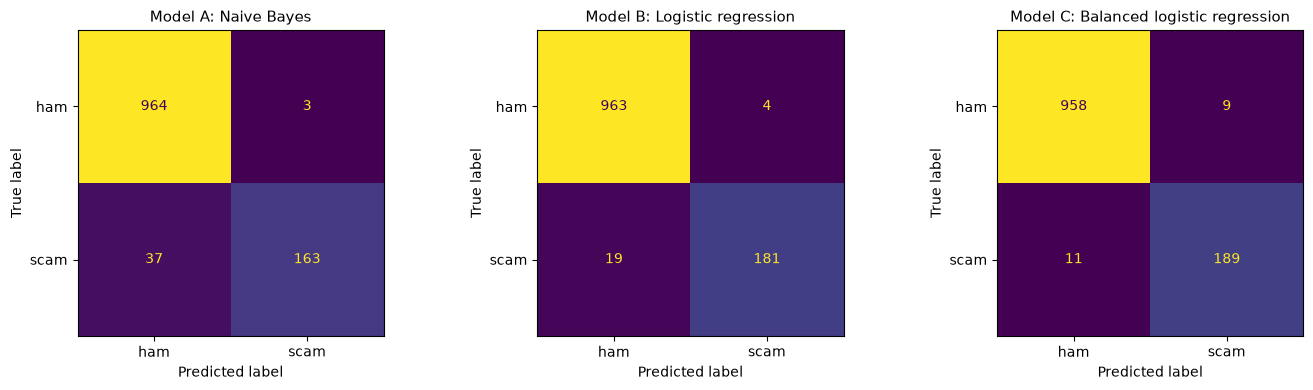

In [12]:
# Confusion matrices on the test set
names = list(models)[1:]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, names):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[name], display_labels=["ham", "scam"], ax=ax, colorbar=False)
    ax.set_title(name.split(" (")[0], fontsize=11)
plt.tight_layout(); plt.show()

Out of 200 test scams, Naive Bayes misses 37, Model B misses 19, and Model C misses only 11. Model C flags 9 of 967 real texts at the default 50% cutoff. The next table shows how a higher cutoff removes those false alarms.

In [13]:
# Block / warn thresholds for the final model (Model C)
probs = final.predict_proba(X_test_B)[:, 1]
rows = []
for t in [0.3, 0.5, 0.7, 0.9, 0.95, 0.99]:
    pred = probs >= t
    rows.append({"threshold": t, "scams caught (of 200)": int((pred & (y_test == 1)).sum()),
                 "real texts flagged (of 967)": int((pred & (y_test == 0)).sum())})
pd.DataFrame(rows)

,threshold,scams caught (of 200),real texts flagged (of 967)
0,0.30,191,12
1,0.50,189,9
2,0.70,185,6
3,0.90,176,2
4,0.95,173,0
5,0.99,155,0


The model outputs a probability, so the carrier can choose its own cutoffs. At 95%, the model still catches 173 of 200 scams (86.5%) and flags zero real texts. This supports a three tier workflow: block at 95% or higher, warn between 50% and 95%, and deliver below 50%.

### 5.4 Which features matter

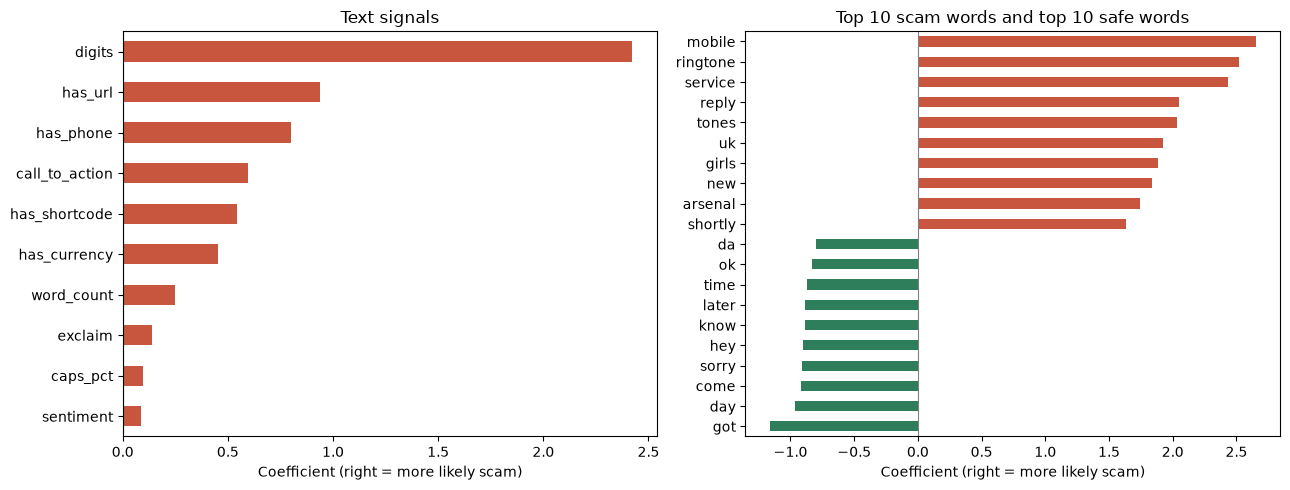

digits            2.42
has_url           0.94
has_phone         0.80
call_to_action    0.60
has_shortcode     0.54
has_currency      0.45
word_count        0.25
exclaim           0.14
caps_pct          0.10
sentiment         0.09


In [14]:
# Which features push a message toward scam (Model C coefficients)
feature_names = list(tfidf.get_feature_names_out()) + list(S_train.columns)
coefs = pd.Series(final.coef_[0], index=feature_names)
signal_coefs = coefs[list(S_train.columns)].sort_values()
word_coefs = coefs.drop(S_train.columns)
top_words = pd.concat([word_coefs.nsmallest(10), word_coefs.nlargest(10)]).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
signal_coefs.plot.barh(ax=axes[0], color=["#C8553D" if v > 0 else "#2E7D5B" for v in signal_coefs])
axes[0].set_title("Text signals"); axes[0].axvline(0, color="grey", lw=0.8)
top_words.plot.barh(ax=axes[1], color=["#C8553D" if v > 0 else "#2E7D5B" for v in top_words])
axes[1].set_title("Top 10 scam words and top 10 safe words"); axes[1].axvline(0, color="grey", lw=0.8)
for ax in axes: ax.set_xlabel("Coefficient (right = more likely scam)")
plt.tight_layout(); plt.show()
print(signal_coefs.sort_values(ascending=False).round(2).to_string())

Because all signals are standardized, their coefficients can be compared directly. Digit count is by far the strongest signal (2.42), followed by links (0.94), phone numbers (0.80) and calls to action (0.60). Sentiment and capital letters add little once the other features are in the model.

The strongest scam words are "mobile," "ringtone," "service," "reply" and "uk," and the strongest safe words are everyday conversation such as "got," "day," "come," "sorry" and "hey." The scam words reflect the older UK marketing texts in the dataset, which is a warning that the word features may not carry over to modern U.S. scams.

### 5.5 Sanity check: is it just learning "phone number = scam"?

In Phase 1 we noticed the original PHONE flag was almost a giveaway (527 of 638 smishing texts vs. 7 of 4,844 ham). A model that only learned "phone number means scam" would fail on real pharmacy or doctor's office texts. We retrained Model C with no phone, digit or short code information at all, including removing numbers from the vocabulary.

In [15]:
# Sanity check: does the model just learn "phone number = scam"?
# Retrain with no phone, digit or short code information at all (numbers removed from the vocabulary too)
tfidf_l = TfidfVectorizer(stop_words="english", min_df=2, max_df=0.9, token_pattern=r"(?u)\b[a-zA-Z]{2,}\b")
keep = [c for c in S_train.columns if c not in ("has_phone", "digits", "has_shortcode")]
sc = StandardScaler()
Xtr = hstack([tfidf_l.fit_transform(train_df["TEXT"]), csr_matrix(sc.fit_transform(S_train[keep]))]).tocsr()
Xte = hstack([tfidf_l.transform(test_df["TEXT"]), csr_matrix(sc.transform(S_test[keep]))]).tocsr()
no_digits = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xtr, y_train)
p = no_digits.predict(Xte)
print(f"No phone or digit info: precision {precision_score(y_test, p):.3f}, recall {recall_score(y_test, p):.3f}, F1 {f1_score(y_test, p):.3f}")

no_phone = ((test_df["scam"] == 1) & ~test_df["TEXT"].str.contains(r"\d{10,}")).values
print("Test scams with no phone number:", no_phone.sum())
print("  caught by the no-digit model:", round(no_digits.predict(Xte[no_phone]).mean(), 3))
print("  caught by the full model C:  ", round(final.predict(X_test_B[no_phone]).mean(), 3))

No phone or digit info: precision 0.909, recall 0.900, F1 0.905
Test scams with no phone number: 80
  caught by the no-digit model: 0.838
  caught by the full model C:   0.862


Without any number information the model still reaches an F1 of 0.905 (recall 0.900), and on the 80 test scams with no phone number the full model catches 86.2%. Digits clearly help, but the model also relies on vocabulary, links and calls to action, so it is not a one feature shortcut.

### 5.6 Where the model fails

In [16]:
# What does the final model get wrong?
test_view = test_df[["LABEL", "TEXT"]].assign(prob=probs.round(3), pred=(probs >= 0.5).astype(int))
missed = test_view[(test_view.pred == 0) & (y_test == 1)].sort_values("prob")
false_alarms = test_view[(test_view.pred == 1) & (y_test == 0)].sort_values("prob", ascending=False)
print("Recall by original label (share of test scams caught at 50%):")
print(test_view[y_test == 1].groupby("LABEL")["pred"].agg(caught="sum", total="count", recall="mean").round(3))
print("\nMissed scams:", len(missed), "| by original label:", missed["LABEL"].value_counts().to_dict())
display(missed.head(6))
print("False alarms:", len(false_alarms))
display(false_alarms)

Recall by original label (share of test scams caught at 50%):
          caught  total  recall
LABEL                          
smishing     108    108    1.00
spam          81     92    0.88

Missed scams: 11 | by original label: {'spam': 11}


,LABEL,TEXT,prob,pred
3569,spam,How come it takes so little time for a child who is afraid of the dark to become a teenager who wants to stay out al...,0.021,0
5421,spam,lam Frederick banner. Pls conatct me asap regarding a possible late,0.021,0
2334,spam,This message is brought to you by GMW Ltd. and is not connected to the,0.043,0
5127,spam,Only 1 day left for SAWAN KI BAHAR compt. for Agents/DOs/CLIAs. Qualify the competition and win maximum prizes...SDM,0.045,0
2089,spam,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo,0.053,0
5198,spam,"Hi this is Amy, we will be sending you a free phone number in a couple of days, which will give you an access to all...",0.074,0


False alarms: 9


,LABEL,TEXT,prob,pred
2007,ham,Message:some text missing* Sender:Name Missing* *Number Missing *Sent:Date missing *Missing U a lot thats y everythi...,0.928,1
4493,ham,My tuition is at 330. Hm we go for the 1120 to 1205 one? Do you mind?,0.921,1
2492,ham,This is ur face test ( 1 2 3 4 5 6 7 8 9 ) select any number i will tell ur face astrology.... am waiting. quick...,0.877,1
3728,ham,"Solve d Case : A Man Was Found Murdered On 13 jan AfterNoon. 1,His wife called Police. 2,Police questioned everyone....",0.826,1
5455,ham,Your opinion about me? 1. Oversmart 2. selfish 3. naughy 4. Lovable 5. Silent 6. Special 7. immature 8. Stylish 9. S...,0.813,1
5110,ham,Actually i deleted my old website..now i m blogging at magicalsongs.blogspot.com,0.758,1
4902,ham,"Solve d Case : A Man Was Found Murdered On 19 october, AfterNoon. 1,His wife called Police. 2,Police questioned ever...",0.677,1
3373,ham,Can you plz tell me the answer. Reeta sent via fullonsms.com,0.585,1
1848,ham,"Good evening Sir, hope you are having a nice day. I wanted to bring it to your notice that I have been late in payin...",0.512,1


Every missed scam is spam (marketing); the model caught all 108 smishing texts in the test set (spam recall is 0.88). The missed messages are mostly cut off mid sentence (the dataset was converted from screenshots, so some texts are truncated), written in a mix of English and Hindi, or look like ordinary messages ("Hi this is Amy..."). The false alarms are real texts that look like scams on the surface: chain messages with numbered lists, texts sent through SMS forwarding websites (which add a ".com" link), and a polite message about a late payment. All of them score below 95%, so none would be blocked under the three tier workflow.

The example messages below show the same pattern. The modern U.S. package scam is warned rather than blocked, and the real verification code is warned because its digits push the score up.

In [17]:
# Example messages through the final model, with the carrier's action
def scam_test(message):
    X = hstack([tfidf.transform([message]), csr_matrix(scaler.transform(signal_features([message])))]).tocsr()
    prob = final.predict_proba(X)[0, 1]
    action = "Block" if prob >= 0.95 else "Warn" if prob >= 0.5 else "Deliver"
    return {"message": message, "chance it's a scam": f"{prob:.1%}", "action": action}

pd.DataFrame([scam_test(m) for m in [
    "Hey, are we still meeting for lunch at noon?",
    "URGENT! You have won a £1000 prize. Call 09061701461 now to claim. T&C apply",
    "Your package could not be delivered. Update your address at usps-redelivery.com",
    "Your verification code is 482913. Do not share it with anyone.",
]])

,message,chance it's a scam,action
0,"Hey, are we still meeting for lunch at noon?",1.2%,Deliver
1,URGENT! You have won a £1000 prize. Call 09061701461 now to claim. T&C apply,100.0%,Block
2,Your package could not be delivered. Update your address at usps-redelivery.com,83.8%,Warn
3,Your verification code is 482913. Do not share it with anyone.,62.7%,Warn


In [18]:
# Save the final model for the Scam Checker notebook
import joblib
os.makedirs("../models", exist_ok=True)
joblib.dump({"tfidf": tfidf, "scaler": scaler, "model": final}, "../models/scam_model.joblib")
print("Saved models/scam_model.joblib")

Saved models/scam_model.joblib


## 6. Key findings

* Scam texts are structurally different from real ones. About three in four scams contain a call to action vs. fewer than one in ten real texts, and scams average about 15 digits vs. 0.3. Spam and smishing are nearly identical on these signals, so one "scam" class was the right target.
* The Phase 2 text signals caught more scams. Adding them to the word features raised scam recall from 0.815 to 0.905, and balancing the classes raised it to 0.945 (F1 0.950), compared with a recall of 0 for the always ham baseline.
* The model does not depend on phone numbers. With all phone and digit information removed it still reaches an F1 of 0.905, and it catches 86.2% of scams that contain no phone number.
* At a 95% cutoff the model blocks 86.5% of scams with zero real texts blocked, and every scam it misses at the default cutoff is low risk marketing spam, not smishing.

## 7. Business implications and recommendations

How the carrier would use it. The features are diagnostic (the carrier cannot change what scammers write), so the model's job is to trigger a workflow for each incoming text:

| Score | Action | Test set result (200 scams, 967 real texts) |
|---|---|---|
| 95% or higher | Block before the customer sees it | 173 scams blocked, 0 real texts blocked |
| 50% to 95% | Deliver with a scam warning | 16 scams warned, 9 real texts warned |
| Below 50% | Deliver normally | 11 scams missed (all marketing spam), 958 real texts delivered |

**Recommendations:**

1. Launch with the three tier workflow above, blocking only at 95% or higher so real messages are never silently lost.
2. Allowlist verified senders such as banks, pharmacies and two factor authentication short codes. This fixes the most likely false alarm (a real verification code scored 62.7%).
3. Retrain on current U.S. data before launch, for example scam reports customers forward to the carrier, and then on a regular schedule. Our data is older and UK heavy, which is why the modern USPS scam was only warned (83.8%) instead of blocked.
4. Monitor two numbers every week: the share of customer reported scams the model missed, and the number of appeals from customers whose real texts were warned or blocked.
5. Treat marketing spam separately from smishing in production. Some marketing texts are wanted (customers opted in), so they should be warned or filtered rather than blocked.

**Limitations and risks:**

* The data comes from the UK and India around 2022, so the vocabulary ("nokia," "ringtone," "uk") does not match modern U.S. scams such as toll, package and bank alerts.
* Only 17.1% of messages are scams and the test set has only 200 of them, so each missed scam moves recall by half a point.
* Scammers adapt. Once a carrier blocks texts with links and phone numbers, scams will change their style, so the model needs ongoing retraining.
* Some texts were truncated when the dataset was converted from screenshots, which hides part of the message from the model.

## 8. Ethical and privacy considerations

**Personal information:** The messages are real texts, and some contain first names, phone numbers and personal details. The dataset is already public on Mendeley Data, and we did not add any new personal data or try to identify anyone. In production, the carrier should score messages without storing their content, and our Scam Checker notebook does not save the messages users type in.

**Under represented groups:** The data reflects UK and Indian English from older phones. Casual slang such as "lor" and "da" is learned as a safe signal, while U.S. English and newer writing styles are barely represented. People whose normal texts include lots of numbers (shift schedules, order numbers, numbered lists) or links are more likely to be wrongly flagged, and our false alarms show exactly this. Older adults are frequent scam targets but have no special representation in the data.

**Who could be harmed by a wrong prediction.**

* A missed scam can cost a customer money or personal information, and the harm falls hardest on people least able to spot scams.
* A wrongly blocked real text could mean a missed bank alert, medical appointment reminder or login code. This is why we recommend blocking only at 95% or higher, an allowlist for verified senders, and an easy way for customers to report a mistake.
* Legitimate small businesses that send opt in marketing could be filtered as spam, since our model treats spam and smishing as one class.

## 9. AI usage log

We used Claude (chat interface, not the API) as a coding and writing assistant. Claude did not label, classify or generate any of the data used for training or testing, and every result in this report comes from code we ran ourselves.

| Phase | Task | How Claude was used | How we verified it |
|---|---|---|---|
| 2 | Cleaning and text signal code | Helped write and debug `load_data` and the regex text signals | Ran every cell, spot checked messages flagged for phone, link and call to action by reading them |
| 3 | Model pipeline | Helped combine TF-IDF and scaled signals and move the signals into `src/scamfeatures.py` so the model and Scam Checker share one function | Confirmed TF-IDF and the scaler are fit on training data only; reran the notebook top to bottom and compared results with class notebooks |
| 3 | Reviewing notebooks | Reviewed our notebooks and suggested extra checks | Ran each check ourselves and reported the results, including where performance dropped |
| 3 | Phone number sanity check | Helped write the cell that retrains the model without phone information | **Claude got this wrong:** the comment it wrote said only the phone feature was removed, but the code also dropped digits and short codes and removed numbers from the vocabulary. The cell also repeated the same print line twice. We caught it by reading the code line by line against its output, then fixed the comment, removed the repeated lines, and described the check accurately in the report as "no phone, digit or short code information" |

## References

Federal Trade Commission. (2025, April 16). *New FTC data show top text message scams of 2024; overall losses to text scams hit $470 million* [Press release]. https://www.ftc.gov/news-events/news/press-releases/2025/04/new-ftc-data-show-top-text-message-scams-2024-overall-losses-text-scams-hit-470-million

Mishra, S., & Soni, D. (2022). *SMS Phishing Dataset for Machine Learning and Pattern Recognition* (Version 1) [Data set]. Mendeley Data. https://data.mendeley.com/datasets/f45bkkt8pr/1

Hutto, C. J., & Gilbert, E. (2014). VADER: A parsimonious rule-based model for sentiment analysis of social media text. *Proceedings of the International AAAI Conference on Web and Social Media, 8*(1).